# CT4101 Milestone 3: Model Comparison Checkpoint
**Project:** Predicting whether a Pokémon is Legendary (binary classification)
**Author:** Cian Flanagan

This notebook builds on `01_data_audit_and_baseline.ipynb`. It uses the same train/test split, the same preprocessing and the same evaluation protocol, so every model is compared fairly. The held-out test set is not used anywhere in this notebook.

## 1. Setup and the same split as Milestone 2
This cell imports the libraries and sets a fixed random seed (42) so my results can be repeated. The paths point to the data and figures folders, and work whether the notebook is run from the project folder or from `notebooks/`.

In [1]:
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier

warnings.filterwarnings("ignore")
RANDOM_STATE = 42

# Find the project folder: it is the folder that contains data/pokemon.csv
ROOT = Path.cwd()
if not (ROOT / "data" / "pokemon.csv").exists():
    ROOT = ROOT.parent
DATA_PATH = ROOT / "data" / "pokemon.csv"
FIG_DIR = ROOT / "reports" / "figures"
FIG_DIR.mkdir(parents=True, exist_ok=True)
if not DATA_PATH.exists():
    raise FileNotFoundError(f"Cannot find {DATA_PATH}. Save this notebook inside the project's notebooks/ folder, next to data/pokemon.csv.")
print("Using data file:", DATA_PATH)

sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 200)

Using data file: c:\Users\Cian\Downloads\233891703_2 (1)\data\pokemon.csv


This cell loads the data and recreates exactly the same stratified 80/20 train/test split as Milestone 2. The `assert` stops the notebook with an error if the split ever changes, so all models are compared on the same data. The test set stays locked.

In [2]:
df = pd.read_csv(DATA_PATH)

num_cols = ["height_dm", "weight_hg", "hp", "attack", "defense",
            "special_attack", "special_defense", "speed"]
cat_cols = ["type_1", "type_2", "generation"]
target_col = "is_legendary"

X = df[num_cols + cat_cols].copy()
X["type_2"] = X["type_2"].fillna("none")
y = df[target_col].astype(int)

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, stratify=y, random_state=RANDOM_STATE
)

assert (len(X_train), y_train.sum(), len(X_test), y_test.sum()) == (1080, 96, 271, 24)
print(f"Train: {len(X_train)} rows, {y_train.sum()} Legendary | Test: {len(X_test)} rows, {y_test.sum()} Legendary (locked)")

Train: 1080 rows, 96 Legendary | Test: 271 rows, 24 Legendary (locked)


This cell defines the preprocessing: median imputation and scaling for the numeric columns and a "none" fill plus one-hot encoding for the categorical columns. It also sets up 5-fold stratified cross-validation and the metrics I will report. Everything is inside a pipeline so it is only fitted on the training folds to avoids data leakage.

In [3]:
numeric_pipe = Pipeline([
    ("impute", SimpleImputer(strategy="median")),
    ("scale", StandardScaler()),
])
categorical_pipe = Pipeline([
    ("impute", SimpleImputer(strategy="constant", fill_value="none")),
    ("onehot", OneHotEncoder(handle_unknown="ignore")),
])
preprocess = ColumnTransformer([
    ("num", numeric_pipe, num_cols),
    ("cat", categorical_pipe, cat_cols),
])

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
scoring = {
    "accuracy": "accuracy",
    "balanced_accuracy": "balanced_accuracy",
    "precision": "precision",
    "recall": "recall",
    "f1": "f1",
}

## 2. Evaluation helper
This function cross-validates any model on the training set only and returns its average scores. Using the same function for every model keeps the comparison fair.

In [4]:
def make_pipeline(model):
    return Pipeline([("prep", preprocess), ("model", model)])

def evaluate(name, estimator):
    """Cross-validate on the training set and return one row of metrics."""
    res = cross_validate(estimator, X_train, y_train, cv=cv, scoring=scoring)
    row = {"model": name}
    for m in scoring:
        row[m] = res[f"test_{m}"].mean()
    row["f1_std"] = res["test_f1"].std()
    return row

## 3. Baselines and learned models

**Models and main settings**
- Dummy (most_frequent): always predicts "not Legendary". This is the baseline to beat.
- Dummy (stratified): guesses randomly in the class proportions.
- Logistic Regression (reference from Milestone 2): `max_iter=1000`.
- K-Nearest Neighbours: default settings, k = 5, uniform weights. It classifies by a vote of the 5 most similar Pokémon.
- Decision Tree: default settings, no depth limit, `random_state=42`. It is a flowchart of yes/no questions on the stats.
- Random Forest: default settings, 100 trees, `random_state=42`. It averages many trees trained on random parts of the data.

I used default settings for all models so the comparison is simple and fair. No tuning was done, and tuning is listed as a next step.

This cell runs all six models under the same 5-fold cross-validation and puts the results in one table.

In [5]:
default_models = {
    "Dummy (most_frequent)": DummyClassifier(strategy="most_frequent"),
    "Dummy (stratified)": DummyClassifier(strategy="stratified", random_state=RANDOM_STATE),
    "Logistic Regression (reference)": LogisticRegression(max_iter=1000, random_state=RANDOM_STATE),
    "KNN (k=5)": KNeighborsClassifier(),
    "Decision Tree": DecisionTreeClassifier(random_state=RANDOM_STATE),
    "Random Forest": RandomForestClassifier(random_state=RANDOM_STATE),
}

rows = [evaluate(name, make_pipeline(model)) for name, model in default_models.items()]
results = pd.DataFrame(rows).set_index("model").round(3)
results

,accuracy,balanced_accuracy,precision,recall,f1,f1_std
model,,,,,,
Dummy (most_frequent),0.911,0.500,0.000,0.000,0.000,0.000
Dummy (stratified),0.853,0.496,0.080,0.063,0.070,0.024
Logistic Regression (reference),0.934,0.714,0.717,0.447,0.535,0.129
KNN (k=5),0.924,0.677,0.624,0.376,0.457,0.104
Decision Tree,0.926,0.786,0.597,0.615,0.597,0.055
Random Forest,0.951,0.743,0.917,0.491,0.637,0.079


**Reading the table**
- All three learned models beat both dummies on F1 for the Legendary class.
- Random Forest has the best F1 (about 0.64) and very high precision (about 0.92), but its recall is only about 0.49.
- Decision Tree has the highest recall (about 0.62) but lower precision (about 0.60).
- KNN is the weakest of the three (F1 about 0.46).
- With only 96 Legendary Pokémon in training, F1 varies between folds (see `f1_std`), so small differences should not be over-interpreted.
- Accuracy is 91-95% for every model, so it cannot be used to pick a winner.

This chart plots F1 for each model so the comparison is easy to see. The error bars show how much F1 varies between the 5 folds.

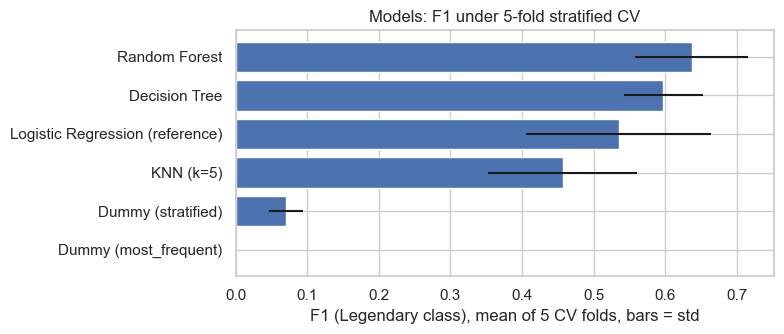

In [6]:
fig, ax = plt.subplots(figsize=(8, 3.5))
order = results["f1"].sort_values()
ax.barh(order.index, order.values, xerr=results.loc[order.index, "f1_std"], color="#4C72B0")
ax.set_xlabel("F1 (Legendary class), mean of 5 CV folds, bars = std")
ax.set_title("Models: F1 under 5-fold stratified CV")
plt.tight_layout()
plt.savefig(FIG_DIR / "m3_f1_comparison.png", dpi=150)
plt.show()

## 4. Visualisation: confusion matrix for the best model
I take the Random Forest (best F1) and get cross validated predictions on the training set so each Pokémon is predicted by a model that never saw it. The confusion matrix shows how many Legendaries it found, missed and wrongly flagged. The test set is not used.

Random Forest (CV on train): TN=980  FP=4  FN=48  TP=48
Precision = 0.923 | Recall = 0.500


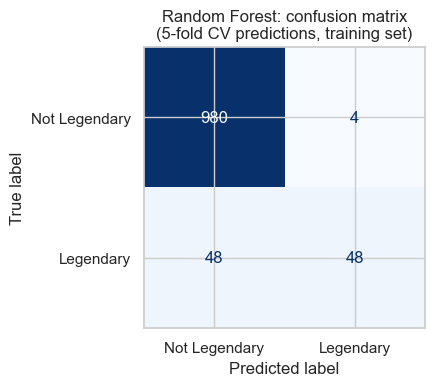

In [7]:
from sklearn.model_selection import cross_val_predict
from sklearn.metrics import ConfusionMatrixDisplay, confusion_matrix

rf_pipe = make_pipeline(RandomForestClassifier(random_state=RANDOM_STATE))
proba_rf = cross_val_predict(rf_pipe, X_train, y_train, cv=cv, method="predict_proba")[:, 1]
pred_rf = (proba_rf >= 0.5).astype(int)

cm = confusion_matrix(y_train, pred_rf)
tn, fp, fn, tp = cm.ravel()
print(f"Random Forest (CV on train): TN={tn}  FP={fp}  FN={fn}  TP={tp}")
print(f"Precision = {tp / (tp + fp):.3f} | Recall = {tp / (tp + fn):.3f}")

fig, ax = plt.subplots(figsize=(4.5, 4.5))
ConfusionMatrixDisplay(cm, display_labels=["Not Legendary", "Legendary"]).plot(ax=ax, colorbar=False, cmap="Blues")
ax.set_title("Random Forest: confusion matrix\n(5-fold CV predictions, training set)")
plt.tight_layout()
plt.savefig(FIG_DIR / "m3_rf_confusion_matrix.png", dpi=150)
plt.show()

**Reading the confusion matrix.** Out of 96 Legendary Pokémon in training, the model finds 48 (recall about 0.50) and misses 48. It raises only 4 false alarms among 984 non-Legendary Pokémon. So the model is very cautious: when it says "Legendary" it is almost always right but it misses half of them.

## 5. Error analysis: where does the model go wrong?
This cell lists the Pokémon the Random Forest gets wrong: the Legendaries it missed (false negatives) and the non Legendaries it flagged (false positives), with their stats and predicted probability.

In [8]:
info_cols = ["name", "type_1", "hp", "attack", "defense", "special_attack", "special_defense", "speed", "is_mythical"]
errors = df.loc[X_train.index, info_cols].copy()
errors["prob_legendary"] = proba_rf.round(2)
errors["is_legendary"] = y_train.values
errors["predicted"] = pred_rf

false_neg = errors[(errors.is_legendary == 1) & (errors.predicted == 0)].sort_values("prob_legendary")
false_pos = errors[(errors.is_legendary == 0) & (errors.predicted == 1)].sort_values("prob_legendary", ascending=False)

print(f"False negatives (Legendary missed): {len(false_neg)}")
display(false_neg.head(10))
print(f"False positives (non-Legendary flagged): {len(false_pos)}")
display(false_pos)

False negatives (Legendary missed): 48


,name,type_1,hp,attack,defense,special_attack,special_defense,speed,is_mythical,prob_legendary,is_legendary,predicted
890,kubfu,fighting,60,90,60,53,50,72,False,0.00,1,0
1205,zygarde-10,dragon,54,100,71,61,85,115,False,0.01,1,0
1023,terapagos,normal,90,65,85,65,85,60,False,0.02,1,0
1273,enamorus-therian,fairy,74,115,110,135,100,46,False,0.03,1,0
897,calyrex,psychic,100,80,80,80,80,80,False,0.03,1,0
376,regirock,rock,80,100,200,50,100,50,False,0.04,1,0
788,cosmog,psychic,43,29,31,29,31,37,False,0.05,1,0
1014,munkidori,poison,88,75,66,130,90,106,False,0.05,1,0
771,type-null,normal,95,95,95,95,95,59,False,0.06,1,0
641,thundurus-incarnate,electric,79,115,70,125,80,111,False,0.07,1,0


False positives (non-Legendary flagged): 4


,name,type_1,hp,attack,defense,special_attack,special_defense,speed,is_mythical,prob_legendary,is_legendary,predicted
1019,gouging-fire,fire,105,115,121,65,93,91,False,0.63,0,1
1008,walking-wake,water,99,83,91,125,83,109,False,0.58,0,1
1305,dragonite-mega,dragon,91,124,115,145,125,100,False,0.57,0,1
1100,metagross-mega,steel,80,145,150,105,110,110,False,0.52,0,1


This cell looks for patterns in the errors: how many Mythical Pokémon were predicted Legendary, how many false alarms are Mega forms, and whether the missed Legendaries have weaker total stats than the ones the model found.

In [9]:
print("Mythical Pokemon in training set:", int(errors.is_mythical.sum()),
      "| of which predicted Legendary:", int(errors[errors.is_mythical].predicted.sum()))
print("False positives that are Mega forms:", int(false_pos.name.str.contains("mega").sum()), "of", len(false_pos))
print()
stat_cols = ["hp", "attack", "defense", "special_attack", "special_defense", "speed"]
found = errors[(errors.is_legendary == 1) & (errors.predicted == 1)]
print("Median total base stats (sum of the six battle stats):")
print("  Legendaries missed:", false_neg[stat_cols].sum(axis=1).median())
print("  Legendaries found: ", found[stat_cols].sum(axis=1).median())

Mythical Pokemon in training set: 26 | of which predicted Legendary: 0
False positives that are Mega forms: 2 of 4

Median total base stats (sum of the six battle stats):
  Legendaries missed: 580.0
  Legendaries found:  680.0


**Error analysis findings**
- **Missed Legendaries (48):** many have modest or unusual stats, e.g. `kubfu`, `cosmog`, `type-null` and `terapagos`. Their Legendary status comes from the games' design, not their stats, so a stats-only model cannot recognise them. Others, such as `tapu-koko` and `regirock`, look like strong ordinary Pokémon.
- **Stats do separate them:** the median total of the six battle stats is about 580 for missed Legendaries against about 680 for found ones, so the model mainly catches the Legendaries with the very highest stats.
- **False alarms (only 4):** `gouging-fire`, `walking-wake`, `dragonite-mega` and `metagross-mega` are all very strong non-Legendary Pokémon, and two are Mega evolutions.
- **Mythical Pokémon:** none of the 26 in training was predicted Legendary, so the model is not simply confusing them with Legendaries here.
- **Overall pattern:** the model is cautious. It only says "Legendary" when the stats are extremely high, giving high precision but only about 50% recall. Lowering the decision threshold would trade some precision for more recall.
- **Data limitation:** Mega and regional forms are separate rows, so related Pokémon (e.g. `garchomp` and `garchomp-mega`) can land in different CV folds, which may make the CV scores slightly optimistic.

## 6. Draft conclusion

**Current best model: Random Forest (default settings, 100 trees).**

| Model | Precision | Recall | F1 |
|---|---|---|---|
| Dummy (most_frequent) | 0.00 | 0.00 | 0.00 |
| Logistic Regression (reference) | 0.72 | 0.45 | 0.54 |
| KNN (k=5) | 0.62 | 0.38 | 0.46 |
| Decision Tree | 0.60 | 0.62 | 0.60 |
| **Random Forest** | **0.92** | **0.49** | **0.64** |

*(5-fold stratified cross-validation on the training set.)*

**Evidence.** The Random Forest has the highest F1 and the highest precision. All three learned models beat the dummy baselines, so physical and battle stats carry real signal about Legendary status. The Decision Tree has the best recall, so the best choice depends on whether missing a Legendary or raising a false alarm is the costlier mistake.

**Limitations.**
- Only 96 Legendary examples in training, so scores are noisy and small gaps between models are not reliable.
- Legendary status is defined by game design and lore, not only by stats, so some Legendaries cannot be found from stats alone.
- Mythical Pokémon are labelled non-Legendary but have similar stats (label noise).
- Alternate forms (Mega, regional) are separate rows, which may make CV slightly optimistic.
- Models use default settings with no tuning.

**Next steps.**
1. Tune the models with a small grid search, using cross-validation on the training set only.
2. Try lowering the decision threshold to improve recall.
3. Evaluate the chosen model once on the locked test set.
4. Try grouped CV by species, and another model such as gradient boosting.
5. Write up the responsible-ML considerations (intended use, risks, interpretability).

## Assistance declaration
- Dataset: Kaggle "Pokemon Stats Dataset" (see `data/README.md` for source and licence).
- Generative AI / coding assistant: Claude (Anthropic) drafted the code and explanations for this notebook. I added it section by section, ran and tested each part, and reviewed the results. I understand the methods and decisions.
- No external collaboration. No other external code beyond scikit-learn / pandas / seaborn documentation examples.